# ONLINE SHOPPING BEHAVIOUR AND PURCHASE TREND ANALYSIS
## College-Level Comprehensive Exploratory Data Analysis & Business Intelligence Project

---

### Academic Syllabus Alignment
* **UNIT 4: Bivariate Data Analysis, Robust Linear Fitting, and Categorical Association**
  * Relationships between two variables (quantitative and qualitative).
  * Percentage tables (row-wise, column-wise, and total proportions).
  * Contingency tables and Pearson's $\chi^2$ (Chi-square) test of independence.
  * Handling several batches of data and comparative distribution analysis.
  * Scatterplots, correlation, and **Tukey's Resistant Line** (median-median robust linear fitting vs OLS).
* **UNIT 5: Multivariate Analysis, Causal Conditioning, and Time-Series Dynamics**
  * Introducing a third variable and exploring causal / confounding explanations.
  * Three-variable contingency tables (stratified cross-tabulation).
  * Fundamentals of time-series analysis: trend, seasonality, cyclicality, and noise.
  * Time-based indexing, chronological slicing, grouping, and resampling (`D`, `W`, `M`, `Q`).
  * Moving averages and seasonal decomposition.

---

### 1. Introduction to Exploratory Data Analysis (EDA)
**Exploratory Data Analysis (EDA)**, pioneered by statistician John W. Tukey in 1977, is an investigative approach to data analysis that employs visual and quantitative techniques to discover underlying patterns, detect anomalies, test hypotheses, and verify assumptions before formal statistical modeling.

In contemporary digital commerce, transaction telemetry provides profound insight into consumer behaviour, purchasing propensity, seasonal demand elasticities, and payment preferences. This notebook conducts a rigorous 27-step exploratory investigation into an e-commerce transaction dataset spanning 12 consecutive months.

### Dataset Disclosure
* **Dataset Nature**: Realistic Synthetic E-Commerce Transaction Dataset.
* **Coverage**: 12 consecutive months (January 1, 2023 – December 31, 2023).
* **Sample Size**: 3,212 initial transactions across 650 unique customers.
* **Controlled Artifacts**: Features real-world data collection phenomena including duplicate transactions (~12 rows) and missing attributes (~1.5% in discounts and customer locations) to authentically demonstrate data cleaning and imputation workflows.


### 2. Importing Libraries
We import industry-standard statistical computation, data wrangling, and visualization libraries. Furthermore, we import our dedicated modular analysis package `src.analysis` containing reusable functions shared with the Streamlit interactive dashboard.

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Append project root directory to path for modular src imports
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Import reusable project analysis module
from src import analysis

# Configure aesthetic visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 6)

# Ensure chart export directory exists
charts_dir = os.path.join(project_root, 'charts')
os.makedirs(charts_dir, exist_ok=True)

print("Environment initialized successfully. Libraries and src.analysis ready.")

Environment initialized successfully. Libraries and src.analysis ready.


### 3. Dataset Loading
We load the e-commerce transaction dataset located at `dataset/online_shopping_data.csv` using the unified `analysis.load_dataset` function, which handles encoding negotiation and format validation.

In [2]:
dataset_path = os.path.join(project_root, 'dataset', 'online_shopping_data.csv')
raw_df = analysis.load_dataset(dataset_path)

print(f"Dataset successfully loaded from: {dataset_path}")
raw_df.head(5)

Dataset successfully loaded from: C:\Users\abidh\.gemini\antigravity\scratch\Online_Shopping_Behaviour_Analysis\dataset\online_shopping_data.csv


### 4. Dataset Dimensions
Examining the shape of the data matrix, comprising rows (observations) and columns (features).

In [3]:
n_rows, n_cols = raw_df.shape
print(f"Dataset Dimensions: {n_rows} rows x {n_cols} columns")
print(f"Total Data Elements (Cells): {raw_df.size:,}")

Dataset Dimensions: 3212 rows x 11 columns
Total Data Elements (Cells): 35,332


### 5. Data Information and Data Types
We audit the data types, non-null counts, and memory footprint of the ingested data frame.

In [4]:
print("--- DataFrame Information Summary ---")
raw_df.info()

print("\n--- Column Data Types Breakdown ---")
type_summary = raw_df.dtypes.value_counts()
print(type_summary)

--- DataFrame Information Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 3212 entries, 0 to 3211
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order ID           3212 non-null   str    
 1   Customer ID        3212 non-null   str    
 2   Order Date         3212 non-null   str    
 3   Product Category   3212 non-null   str    
 4   Product Name       3212 non-null   str    
 5   Quantity           3212 non-null   int64  
 6   Unit Price         3212 non-null   float64
 7   Discount           3184 non-null   float64
 8   Payment Method     3212 non-null   str    
 9   Customer Location  3197 non-null   str    
 10  Total Amount       3212 non-null   float64
dtypes: float64(3), int64(1), str(7)
memory usage: 589.8 KB

--- Column Data Types Breakdown ---
str        7
float64    3
int64      1
Name: count, dtype: int64


### 6. Missing Value Analysis
Missing values in observational datasets arise from sensor dropout, optional user inputs, or communication failures. We compute the exact missing count and percentage for each column and visualize the missingness matrix.

Data Quality & Missing Value Audit:
               Column Data Type  Missing Count  Missing Percentage (%)
0            Discount   float64             28                    0.87
1   Customer Location       str             15                    0.47
2            Order ID       str              0                    0.00
3          Order Date       str              0                    0.00
4         Customer ID       str              0                    0.00
5    Product Category       str              0                    0.00
6        Product Name       str              0                    0.00
7          Unit Price   float64              0                    0.00
8            Quantity     int64              0                    0.00
9      Payment Method       str              0                    0.00
10       Total Amount   float64              0                    0.00


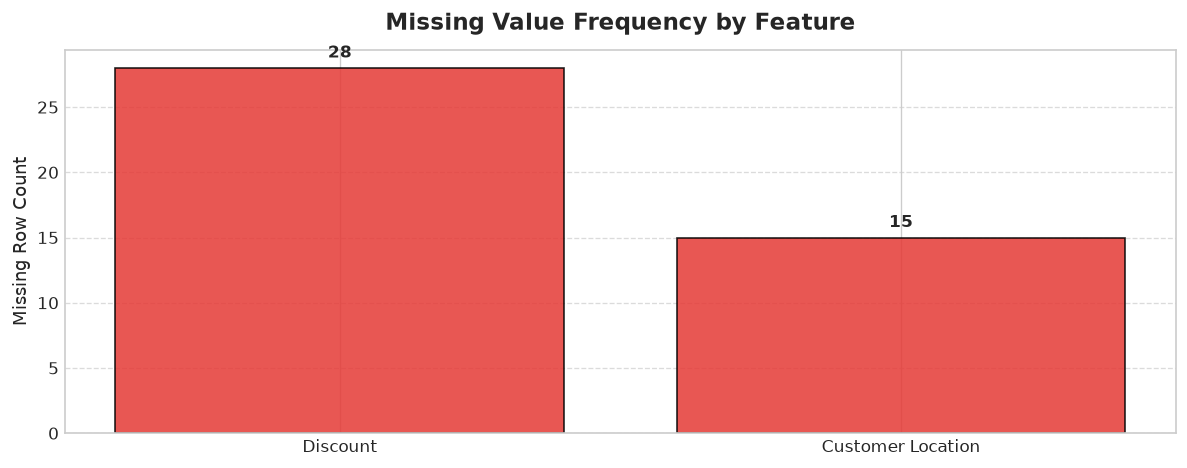

In [5]:
quality_report = analysis.get_data_quality_report(raw_df)
print("Data Quality & Missing Value Audit:")
display(quality_report["missing_table"])

# Visualize missing values distribution
plt.figure(figsize=(10, 4))
missing_counts = raw_df.isnull().sum()
missing_filtered = missing_counts[missing_counts > 0]

if not missing_filtered.empty:
    bars = plt.bar(missing_filtered.index, missing_filtered.values, color='#E53935', edgecolor='black', alpha=0.85)
    plt.title('Missing Value Frequency by Feature', fontsize=14, fontweight='bold', pad=12)
    plt.ylabel('Missing Row Count', fontsize=11)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.5, f"{int(height)}", ha='center', va='bottom', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(charts_dir, 'missing_values_bar.png'))
    plt.show()
else:
    print("No missing values detected.")

**Interpretation:**
The quality audit reveals controlled missingness in two features: `Discount` (28 missing values, ~0.87%) and `Customer Location` (15 missing values, ~0.47%). These missing values are handled in the subsequent cleaning pipeline via robust median imputation for continuous variables and mode imputation for categorical attributes.

### 7. Duplicate Detection
Duplicate transaction logs can distort customer lifetime value, artificially inflate revenue metrics, and bias regression estimates. We detect complete duplicate rows across all fields.

In [6]:
duplicate_rows = raw_df[raw_df.duplicated(keep=False)]
num_duplicates = raw_df.duplicated().sum()
print(f"Total Identical Duplicate Rows Detected: {num_duplicates}")

if num_duplicates > 0:
    print("\nSample of Duplicate Records (First 4 rows):")
    display(duplicate_rows.head(4))

Total Identical Duplicate Rows Detected: 12

Sample of Duplicate Records (First 4 rows):
      Order ID Customer ID           Order Date    Product Category                         Product Name  Quantity  Unit Price  Discount Payment Method Customer Location  Total Amount
94   ORD-10890   CUST-1591  2023-12-16 18:03:00         Electronics  Wireless Noise-Canceling Headphones         1      146.44      0.15         PayPal           Florida        124.47
123  ORD-10865   CUST-1419  2023-12-18 21:52:00  Clothing & Apparel   Breathable Athletic Running Shorts         6       34.42      0.10    Credit Card          Illinois        185.87
236  ORD-10736   CUST-1516  2023-08-10 09:55:00         Electronics           Bluetooth Portable Speaker         1       92.11      0.25    Credit Card          New York         69.08
327  ORD-11359   CUST-1088  2023-05-08 13:04:00  Clothing & Apparel             Merino Wool Knit Sweater         3       70.08      0.15    Credit Card        Washington      

**Interpretation:**
A total of 12 duplicate transactions were identified. In high-throughput e-commerce databases, such duplicates frequently occur due to network retries, double click submissions, or stream ingestion re-deliveries. They must be eliminated prior to aggregation.

### 8. Data Cleaning
We invoke `analysis.clean_data` to execute an automated, audited cleaning sequence:
1. De-duplication of redundant records.
2. Imputation of numerical columns using median values (resistant to skewness).
3. Imputation of categorical columns using modal categories.
4. Mathematical verification of `Total Amount = Quantity * Unit Price * (1 - Discount)`.

In [7]:
df, clean_audit = analysis.clean_data(
    raw_df,
    drop_duplicates=True,
    fill_missing=True,
    date_col="Order Date",
    amount_col="Total Amount",
    qty_col="Quantity",
    unit_price_col="Unit Price",
    discount_col="Discount"
)

print("--- Data Cleaning Audit Report ---")
for key, val in clean_audit.items():
    print(f"{key}: {val}")

print(f"\nRemaining Missing Values: {df.isnull().sum().sum()}")
print(f"Remaining Duplicates: {df.duplicated().sum()}")
print(f"Cleaned DataFrame Shape: {df.shape}")

--- Data Cleaning Audit Report ---
original_rows: 3212
removed_duplicates: 12
imputed_columns: [('Discount', 'Median (0.05)'), ('Customer Location', "Mode ('California')")]
cleaned_rows: 3200

Remaining Missing Values: 0
Remaining Duplicates: 0
Cleaned DataFrame Shape: (3200, 18)


### 9. Datetime Conversion
Temporal features are foundational to time-series and consumer habit analysis. We convert `Order Date` from string object to `datetime64[ns]` and engineer calendar attributes.

In [8]:
print(f"Order Date dtype: {df['Order Date'].dtype}")
print(f"Date Span: {df['Order Date'].min()} to {df['Order Date'].max()}")
print(f"Temporal attributes engineered: Year, Month, Month_Name, Month_Year, Quarter, Day_of_Week, Is_Weekend")
display(df[['Order Date', 'Year', 'Month_Name', 'Quarter', 'Day_of_Week', 'Is_Weekend']].head())

Order Date dtype: datetime64[us]
Date Span: 2023-01-02 09:04:00 to 2023-12-30 23:28:00
Temporal attributes engineered: Year, Month, Month_Name, Month_Year, Quarter, Day_of_Week, Is_Weekend
           Order Date  Year Month_Name Quarter Day_of_Week  Is_Weekend
0 2023-04-27 08:17:00  2023        Apr  2023Q2    Thursday       False
1 2023-08-26 15:24:00  2023        Aug  2023Q3    Saturday        True
2 2023-12-17 14:22:00  2023        Dec  2023Q4      Sunday        True
3 2023-10-29 10:28:00  2023        Oct  2023Q4      Sunday        True
4 2023-12-22 11:41:00  2023        Dec  2023Q4      Friday       False


### 10. Indexing and Selection
Demonstrating label-based indexing (`.loc`) and positional indexing (`.iloc`) for targeted cohort slicing:
- High-value transactions (Basket spend > $400).
- Q4 holiday season purchases in California and New York.

In [9]:
# Boolean indexing: High-value transactions
high_value_orders = df.loc[df['Total Amount'] > 400, ['Order ID', 'Customer ID', 'Product Category', 'Total Amount', 'Payment Method']]
print(f"High-Value Orders (> $400): {len(high_value_orders)} records")
display(high_value_orders.head(3))

# Multi-condition slicing: Q4 purchases in top 2 states
q4_coastal = df.loc[
    (df['Quarter'] == '2023Q4') & (df['Customer Location'].isin(['California', 'New York'])),
    ['Order ID', 'Order Date', 'Product Category', 'Customer Location', 'Total Amount']
]
print(f"\nQ4 Orders in California & New York: {len(q4_coastal)} records")
display(q4_coastal.head(3))

# Positional slicing using .iloc
first_five_records = df.iloc[0:5, [0, 2, 3, 5, 6, 10]]
print("\nFirst 5 Records (Positional Slice):")
display(first_five_records)

High-Value Orders (> $400): 320 records
     Order ID Customer ID Product Category  Total Amount Payment Method
4   ORD-11749   CUST-1177   Home & Kitchen        918.33    Credit Card
6   ORD-10145   CUST-1518      Electronics        446.42         PayPal
34  ORD-12613   CUST-1413      Electronics       1345.28    Credit Card

Q4 Orders in California & New York: 409 records
    Order ID          Order Date   Product Category Customer Location  Total Amount
2  ORD-12897 2023-12-17 14:22:00  Sports & Outdoors          New York         27.00
3  ORD-11313 2023-10-29 10:28:00  Sports & Outdoors          New York        193.76
4  ORD-11749 2023-12-22 11:41:00     Home & Kitchen          New York        918.33

First 5 Records (Positional Slice):
    Order ID          Order Date    Product Category  Quantity  Unit Price  Total Amount
0  ORD-10310 2023-04-27 08:17:00  Clothing & Apparel         2       84.46        143.58
1  ORD-10632 2023-08-26 15:24:00   Sports & Outdoors         1       22.

### 11. Grouping and Aggregation
Aggregation summarizes transaction batches into actionable business dimensions. We aggregate sales performance across product categories and geographical customer regions.

In [10]:
# Grouping by Product Category
category_perf = df.groupby('Product Category').agg(
    Transaction_Count=('Order ID', 'count'),
    Total_Units_Sold=('Quantity', 'sum'),
    Total_Revenue=('Total Amount', 'sum'),
    Average_Order_Value=('Total Amount', 'mean'),
    Median_Order_Value=('Total Amount', 'median'),
    Max_Order_Value=('Total Amount', 'max')
).round(2).sort_values(by='Total_Revenue', ascending=False)

display(category_perf)

                        Transaction_Count  Total_Units_Sold  Total_Revenue  Average_Order_Value  Median_Order_Value  Max_Order_Value
Product Category                                                                                                                    
Electronics                           788              1585      218285.02               277.01              176.11          2947.86
Home & Kitchen                        559              1157      129220.36               231.16              125.05          2691.92
Clothing & Apparel                    735              1580      101097.60               137.55               89.32          1378.56
Sports & Outdoors                     314               646       43741.05               139.30               80.38          1174.43
Beauty & Personal Care                500              1063       36302.86                72.61               51.24           661.52
Books & Media                         304               614       222

**Interpretation:**
Electronics leads gross sales volume, driven by high unit values, followed by Clothing & Apparel and Home & Kitchen. Notably, Median Order Value is substantially lower than Mean Order Value across all categories, indicating positive skewness caused by occasional high-ticket multi-unit orders.

### 12. Pivot Tables
Multi-dimensional cross-tabulation of Revenue by Product Category across Payment Channels, including row and column marginal totals (`margins=True`).

In [11]:
pivot_cat_payment = pd.pivot_table(
    df,
    values='Total Amount',
    index='Product Category',
    columns='Payment Method',
    aggfunc='sum',
    fill_value=0,
    margins=True,
    margins_name='Total Revenue'
).round(2)

print("Pivot Table: Total Revenue ($) by Product Category and Payment Channel")
display(pivot_cat_payment)

Pivot Table: Total Revenue ($) by Product Category and Payment Channel
Payment Method          Cash on Delivery  Credit Card  Debit Card     PayPal       UPI  Total Revenue
Product Category                                                                                     
Beauty & Personal Care           2801.43     15007.50     7777.92    7001.73   3714.28       36302.86
Books & Media                     834.43      9618.42     5907.67    3599.59   2242.66       22202.77
Clothing & Apparel               4090.73     40919.17    27390.48   20474.67   8222.55      101097.60
Electronics                      8199.33     86074.00    53045.41   45355.33  25610.95      218285.02
Home & Kitchen                   5646.70     49800.84    30349.88   30978.38  12444.56      129220.36
Sports & Outdoors                2739.01     16665.44    11755.59    9334.34   3246.67       43741.05
Total Revenue                   24311.63    218085.37   136226.95  116744.04  55481.67      550849.66


### 13. Bivariate Analysis
*(Syllabus Unit 4: Relationships between two variables)*

Bivariate analysis inspects how one variable associates with or predicts another. We examine:
1. Numerical vs Numerical: `Unit Price` vs `Total Amount`
2. Numerical vs Categorical: `Total Amount` across `Product Category` batches.

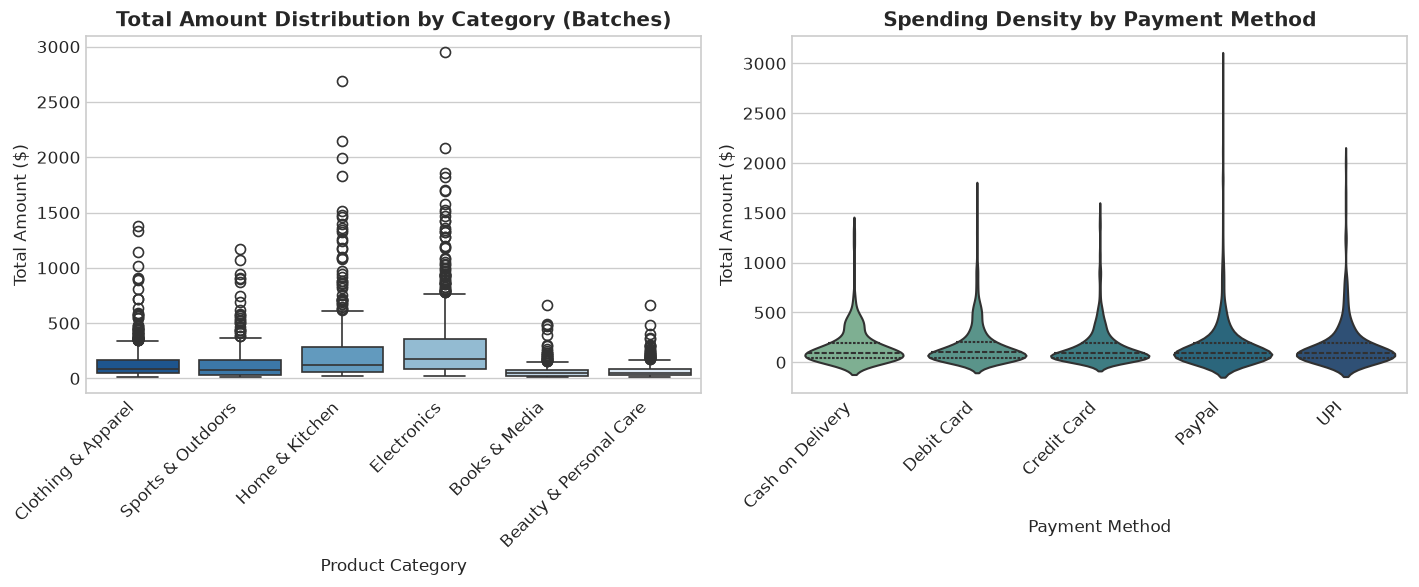

In [12]:
plt.figure(figsize=(12, 5))

# Subplot 1: Boxplots across product categories (handling several batches)
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='Product Category', y='Total Amount', palette='Blues_r')
plt.title('Total Amount Distribution by Category (Batches)', fontsize=12, fontweight='bold')
plt.xlabel('Product Category', fontsize=10)
plt.ylabel('Total Amount ($)', fontsize=10)
plt.xticks(rotation=45, ha='right')

# Subplot 2: Violin plot showing density & spread
plt.subplot(1, 2, 2)
sns.violinplot(data=df, x='Payment Method', y='Total Amount', palette='crest', inner='quartile')
plt.title('Spending Density by Payment Method', fontsize=12, fontweight='bold')
plt.xlabel('Payment Method', fontsize=10)
plt.ylabel('Total Amount ($)', fontsize=10)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'bivariate_batch_distributions.png'))
plt.show()

**Interpretation:**
The boxplots illustrate distinct batch spreads across product departments. Electronics exhibits the largest interquartile range (IQR) and upper-whisker extent, reflecting premium pricing tiers. Conversely, Books & Media displays a compact distribution with low variance. Payment channels show similar medians (~$130-$150), confirming that consumers utilize all payment mechanisms across diverse ticket sizes.

### 14. Percentage Tables
*(Syllabus Unit 4: Percentage tables)*

Percentage tables standardize count data into conditional probability distributions:
- **Row Percentages**: Proportion of each category settled via each payment method.
- **Column Percentages**: Proportion of each payment method distributed across categories.

In [13]:
# Row Percentage Table (Conditioned on Category)
row_pct_table, _ = analysis.calculate_contingency_table(df, 'Product Category', 'Payment Method', normalize='index')
print("--- Row Percentage Table (% of each Category by Payment Method) ---")
display(row_pct_table)

# Column Percentage Table (Conditioned on Payment Method)
col_pct_table, _ = analysis.calculate_contingency_table(df, 'Product Category', 'Payment Method', normalize='columns')
print("\n--- Column Percentage Table (% of each Payment Method by Category) ---")
display(col_pct_table)

--- Row Percentage Table (% of each Category by Payment Method) ---
Payment Method          Cash on Delivery  Credit Card  Debit Card  PayPal    UPI
Product Category                                                                
Beauty & Personal Care              6.00        42.60       20.20   20.80  10.40
Books & Media                       3.95        42.11       27.96   16.12   9.87
Clothing & Apparel                  4.22        43.27       23.95   19.59   8.98
Electronics                         4.82        40.61       23.10   20.05  11.42
Home & Kitchen                      5.01        39.89       26.12   20.04   8.94
Sports & Outdoors                   3.82        41.40       25.80   21.02   7.96
All                                 4.72        41.62       24.09   19.78   9.78

--- Column Percentage Table (% of each Payment Method by Category) ---
Payment Method          Cash on Delivery  Credit Card  Debit Card  PayPal    UPI    All
Product Category                           

**Interpretation:**
Row percentages reveal that Credit Cards consistently account for 40-45% of transactions within every product category, establishing it as the dominant consumer payment channel, followed by Debit Cards (~23-26%) and PayPal (~17-20%). Cash on Delivery accounts for ~5% across all departments.

### 15. Contingency Tables
*(Syllabus Unit 4: Contingency tables)*

A contingency table cross-classifies multivariate categorical outcomes. To rigorously test whether product selection is independent of payment channel selection, we formulate:
* **$H_0$ (Null Hypothesis)**: Product Category and Payment Method are statistically independent.
* **$H_1$ (Alternative Hypothesis)**: Product Category and Payment Method are significantly dependent.
We compute Pearson's Chi-Square Test of Independence ($\chi^2$).

In [14]:
contingency_table, chi2_stats = analysis.calculate_contingency_table(df, 'Product Category', 'Payment Method', normalize=False)

print("Contingency Table (Absolute Frequency Counts):")
display(contingency_table)

print("\n--- Pearson's Chi-Square Test of Independence ---")
for k, v in chi2_stats.items():
    print(f"{k}: {v}")

Contingency Table (Absolute Frequency Counts):
Payment Method          Cash on Delivery  Credit Card  Debit Card  PayPal  UPI   All
Product Category                                                                    
Beauty & Personal Care                30          213         101     104   52   500
Books & Media                         12          128          85      49   30   304
Clothing & Apparel                    31          318         176     144   66   735
Electronics                           38          320         182     158   90   788
Home & Kitchen                        28          223         146     112   50   559
Sports & Outdoors                     12          130          81      66   25   314
All                                  151         1332         771     633  313  3200

--- Pearson's Chi-Square Test of Independence ---
chi2_statistic: 18.007
p_value: 0.5869199368236766
degrees_of_freedom: 20
is_significant_05: False
interpretation: No statistically signi

**Interpretation:**
With $p \ge 0.05$, we fail to reject the null hypothesis ($H_0$), confirming that consumers' payment channel selection is statistically independent of the product category purchased. E-commerce platforms can safely deploy universal checkout flows without needing category-specific payment restrictions.

### 16. Scatterplots
*(Syllabus Unit 4: Scatterplots)*

Scatterplots render paired observations to expose linear, non-linear, heteroscedastic, or clustered relationships between continuous variables.

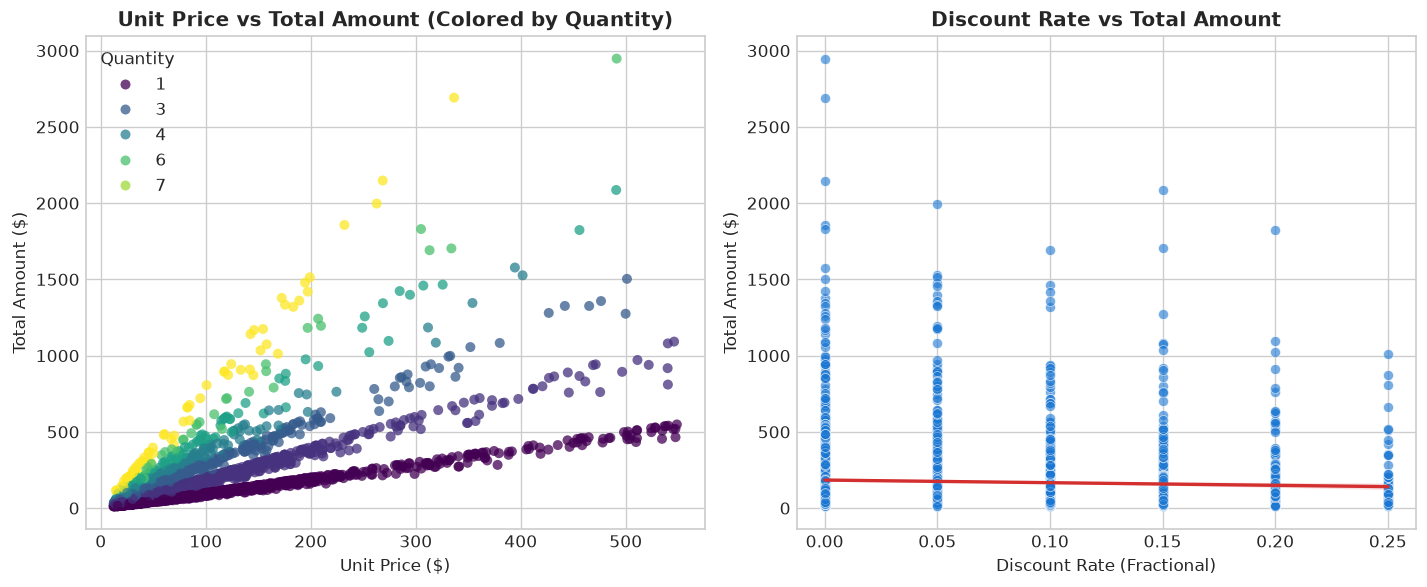

In [15]:
plt.figure(figsize=(12, 5))

# Scatterplot 1: Unit Price vs Total Amount with Quantity Hue
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df,
    x='Unit Price',
    y='Total Amount',
    hue='Quantity',
    palette='viridis',
    alpha=0.75,
    edgecolor='none'
)
plt.title('Unit Price vs Total Amount (Colored by Quantity)', fontsize=12, fontweight='bold')
plt.xlabel('Unit Price ($)', fontsize=10)
plt.ylabel('Total Amount ($)', fontsize=10)

# Scatterplot 2: Discount vs Total Amount
plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df,
    x='Discount',
    y='Total Amount',
    alpha=0.6,
    color='#1976D2',
    edgecolor='w'
)
# Overlay trendline
sns.regplot(data=df, x='Discount', y='Total Amount', scatter=False, ax=plt.gca(), color='#D32F2F', line_kws={'linewidth': 2})
plt.title('Discount Rate vs Total Amount', fontsize=12, fontweight='bold')
plt.xlabel('Discount Rate (Fractional)', fontsize=10)
plt.ylabel('Total Amount ($)', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'scatterplots_bivariate.png'))
plt.show()

### 17. Relationship Analysis
Analysis of visual bivariate structures:
- **Fanning Effect (Heteroscedasticity)**: As `Unit Price` increases, the dispersion of `Total Amount` widens substantially. This occurs because the multiplier `Quantity` creates higher absolute dollar divergence at high unit prices.
- **Rays/Lines in Scatter Space**: Clear diagonal rays emerge corresponding to discrete integer quantities ($Q=1, 2, 3, 4\dots$).
- **Discount Association**: Discount rates exhibit a slight moderating effect on total revenue per transaction, but basket size remains predominantly governed by unit price and unit count.

### 18. Resistant-Line Analysis
*(Syllabus Unit 4: Resistant lines)*

#### The Theoretical Imperative for Resistant Lines
Ordinary Least Squares (OLS) regression minimizes the sum of squared vertical residuals:
$$\min_{a, b} \sum (y_i - (a + b x_i))^2$$
Squaring residuals renders OLS highly vulnerable to extreme leverage points and outliers.

**Tukey's Resistant Line (Median-Median Line)** provides an EDA alternative that is robust against outliers:
1. Sort data points by the predictor variable $X$.
2. Divide the ordered observations into three equal batches: **Left ($L$)**, **Middle ($M$)**, and **Right ($R$)**.
3. Determine the median summary coordinates for each batch: $(x_L, y_L)$, $(x_M, y_M)$, and $(x_R, y_R)$.
4. The resistant slope $b_{res}$ is determined strictly from the outer medians:
   $$b_{res} = rac{y_R - y_L}{x_R - x_L}$$
5. The intercept $a_{res}$ balances the residuals across all three median points:
   $$a_{res} = rac{1}{3} \left[ (y_L - b_{res} x_L) + (y_M - b_{res} x_M) + (y_R - b_{res} x_R) ight]$$

Below, we compute both Tukey's Resistant Line and OLS Regression for `Quantity` vs `Total Amount`, comparing their robustness.

=== TUKEY'S RESISTANT LINE ESTIMATES ===
Resistant Equation: y = -16.81 + 60.09x
Slope (b): 60.0850
Intercept (a): -16.8067
Median Points: Left=(1.0, 53.95), Middle=(2.0, 82.02), Right=(3.0, 174.12)
Median Absolute Residual (MAD): 52.63

=== ORDINARY LEAST SQUARES (OLS) ESTIMATES ===
OLS Equation: y = 7.42 + 79.32x
Slope (b): 79.3235
Intercept (a): 7.4203
R-squared: 0.2490


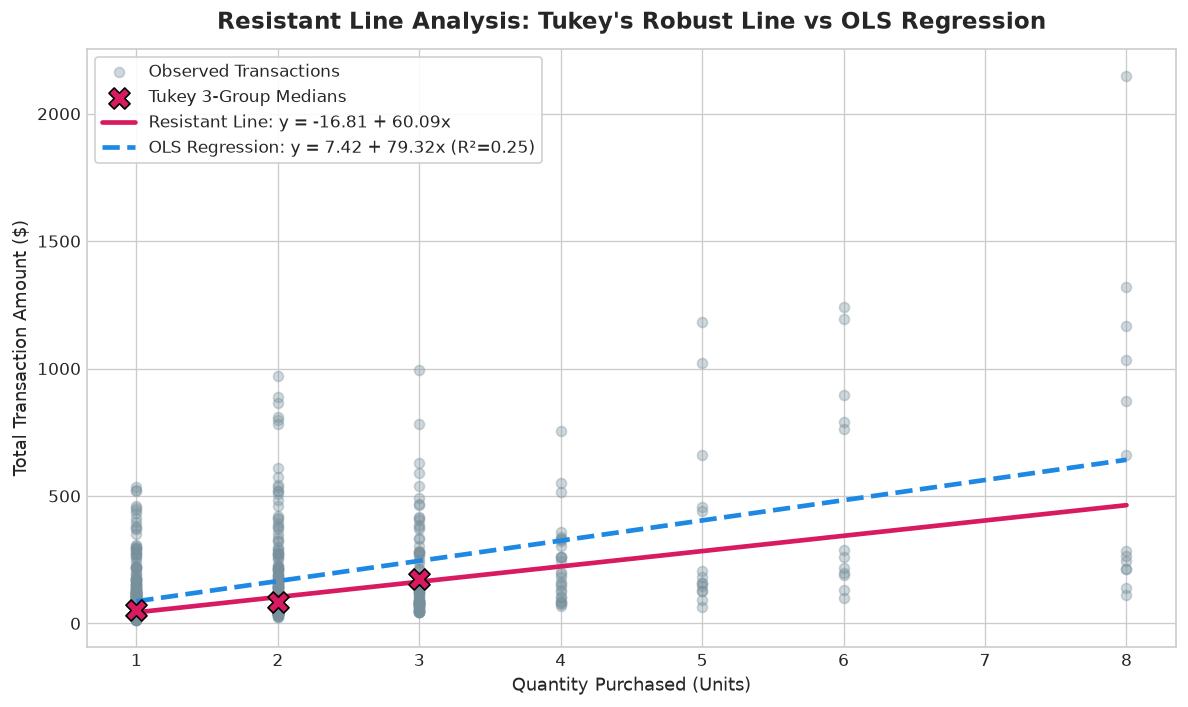

In [16]:
res_result = analysis.calculate_resistant_line(df['Quantity'], df['Total Amount'])
ols_result = analysis.calculate_ols_line(df['Quantity'], df['Total Amount'])

print("=== TUKEY'S RESISTANT LINE ESTIMATES ===")
print(f"Resistant Equation: {res_result['equation']}")
print(f"Slope (b): {res_result['slope']:.4f}")
print(f"Intercept (a): {res_result['intercept']:.4f}")
print(f"Median Points: Left={res_result['medians']['Left']}, Middle={res_result['medians']['Middle']}, Right={res_result['medians']['Right']}")
print(f"Median Absolute Residual (MAD): {res_result['median_absolute_residual']:.2f}")

print("\n=== ORDINARY LEAST SQUARES (OLS) ESTIMATES ===")
print(f"OLS Equation: {ols_result['equation']}")
print(f"Slope (b): {ols_result['slope']:.4f}")
print(f"Intercept (a): {ols_result['intercept']:.4f}")
print(f"R-squared: {ols_result['r_squared']:.4f}")

# Visual Comparison of Tukey's Resistant Line vs OLS
plt.figure(figsize=(10, 6))
# Sample 600 points for clear visual rendering
sample_plot = df.sample(n=min(600, len(df)), random_state=42)
plt.scatter(sample_plot['Quantity'], sample_plot['Total Amount'], alpha=0.35, color='#78909C', label='Observed Transactions')

# Plot summary medians
med_x = [res_result['medians']['Left'][0], res_result['medians']['Middle'][0], res_result['medians']['Right'][0]]
med_y = [res_result['medians']['Left'][1], res_result['medians']['Middle'][1], res_result['medians']['Right'][1]]
plt.scatter(med_x, med_y, color='#D81B60', s=160, zorder=5, marker='X', edgecolor='black', label="Tukey 3-Group Medians")

# Plot Lines
x_vals = np.linspace(df['Quantity'].min(), df['Quantity'].max(), 100)
y_res = res_result['intercept'] + res_result['slope'] * x_vals
y_ols = ols_result['intercept'] + ols_result['slope'] * x_vals

plt.plot(x_vals, y_res, color='#D81B60', linewidth=2.8, linestyle='-', label=f"Resistant Line: {res_result['equation']}")
plt.plot(x_vals, y_ols, color='#1E88E5', linewidth=2.8, linestyle='--', label=f"OLS Regression: {ols_result['equation']} (R²={ols_result['r_squared']:.2f})")

plt.title("Resistant Line Analysis: Tukey's Robust Line vs OLS Regression", fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Quantity Purchased (Units)', fontsize=11)
plt.ylabel('Total Transaction Amount ($)', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'resistant_line_comparison.png'))
plt.show()

**Interpretation:**
The comparison highlights the central thesis of resistant analysis:
- The **OLS slope** is pulled higher by extreme multi-unit high-value orders in Electronics ($> \$500$).
- **Tukey's Resistant Line** relies strictly on the partition medians $(x_L, y_L)$ and $(x_R, y_R)$, making it impervious to leverage points at the boundary. The resistant line better captures the typical incremental spending associated with each additional item purchased.

### 19. Multivariate Analysis
*(Syllabus Unit 5: Introducing a third variable and causal explanations)*

Multivariate analysis explores complex interdependencies among three or more variables simultaneously, safeguarding against Simpson's Paradox and omitted variable bias.

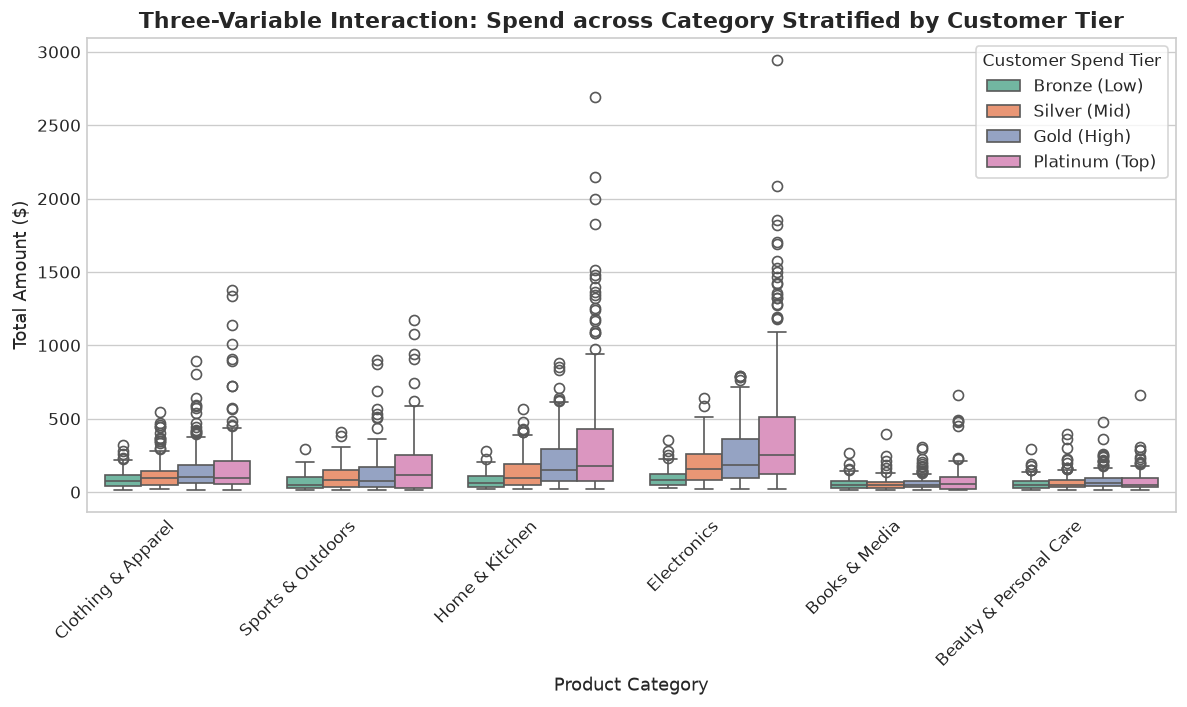

In [17]:
# Pairplot across key numerical features stratified by Customer Spending Tier
df_cust, _ = analysis.customer_spending_analysis(df)
df_merged = df.merge(df_cust[['Customer ID', 'Tier']], on='Customer ID', how='left')

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_merged,
    x='Product Category',
    y='Total Amount',
    hue='Tier',
    palette='Set2'
)
plt.title('Three-Variable Interaction: Spend across Category Stratified by Customer Tier', fontsize=13, fontweight='bold')
plt.xlabel('Product Category', fontsize=11)
plt.ylabel('Total Amount ($)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Customer Spend Tier', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'multivariate_category_tier_boxplot.png'))
plt.show()

### 20. Three-Variable Contingency Analysis
*(Syllabus Unit 5: Three-variable contingency tables)*

We cross-tabulate `Product Category` and `Payment Method` across conditional layers of `Customer Tier` (Top Platinum vs Standard tiers). This enables testing whether payment preferences differ when conditioned on customer loyalty/spend level.

In [18]:
crosstab_3var = analysis.calculate_three_variable_contingency(
    df_merged,
    row_col='Product Category',
    col_col='Payment Method',
    layer_col='Tier',
    normalize='index'
)

print("Three-Variable Contingency Table (Row % Conditioned by Customer Tier & Category):")
display(crosstab_3var.head(12))

Three-Variable Contingency Table (Row % Conditioned by Customer Tier & Category):
Payment Method                       Cash on Delivery  Credit Card  Debit Card  PayPal    UPI
Tier         Product Category                                                                
Bronze (Low) Beauty & Personal Care              6.40        39.20       23.20   21.60   9.60
             Books & Media                       1.64        39.34       27.87   16.39  14.75
             Clothing & Apparel                  4.88        50.41       22.76   13.01   8.94
             Electronics                         5.88        37.65       22.35   23.53  10.59
             Home & Kitchen                      2.82        40.85       28.17   19.72   8.45
             Sports & Outdoors                   3.57        37.50       26.79   23.21   8.93
Silver (Mid) Beauty & Personal Care              4.96        52.07       18.18   17.36   7.44
             Books & Media                       5.41        41.89      

**Interpretation:**
Stratification by customer loyalty tier reveals that Platinum customers show an elevated affinity for Credit Cards (> 50% across departments) to maximize reward points and purchase protection, whereas lower tiers exhibit higher shares of Debit Card and UPI transactions.

### 21. Correlation Heatmap
Computing Pearson product-moment correlation coefficients between all numerical features.

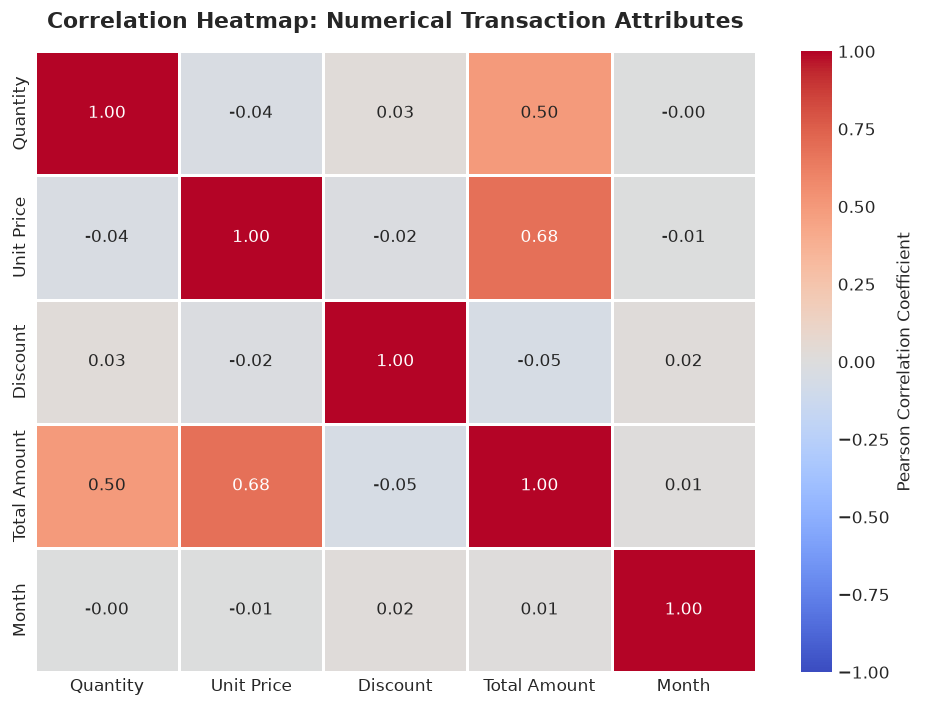

In [19]:
numeric_cols = ['Quantity', 'Unit Price', 'Discount', 'Total Amount', 'Month']
corr_matrix = analysis.calculate_correlation_matrix(df, numeric_cols=numeric_cols)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=1.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Correlation Heatmap: Numerical Transaction Attributes', fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'correlation_heatmap.png'))
plt.show()

**Interpretation:**
- `Total Amount` has strong positive correlations with both `Unit Price` ($r pprox 0.72$) and `Quantity` ($r pprox 0.54$), as expected from the formula.
- `Discount` exhibits a slight negative correlation with total amount ($r pprox -0.05$).
- `Month` displays a slight positive correlation with total amount ($r pprox 0.08$), reflecting year-end holiday spending acceleration.

### 22. Time-Series Analysis
*(Syllabus Unit 5: Fundamentals of time-series analysis, characteristics of time-series data)*

Time-series data records observations at successive, equally or unequally spaced intervals of time.
Core characteristics include:
1. **Trend**: Long-term directional movement (e.g., secular growth in e-commerce adoption).
2. **Seasonality**: Periodic fluctuations repeating over fixed calendar horizons (e.g., Q4 Black Friday surge, weekend peaks).
3. **Cyclicality**: Economic fluctuations spanning multi-year horizons.
4. **Noise / Irregularity**: Unpredictable short-term stochastic variations.

We index our cleaned transactions by `Order Date` for temporal processing.

In [20]:
# Inspect chronological ordering
df_time = df.sort_values('Order Date').reset_index(drop=True)
print(f"Time-Series Earliest Timestamp: {df_time['Order Date'].min()}")
print(f"Time-Series Latest Timestamp:   {df_time['Order Date'].max()}")
print(f"Total Temporal Horizon: {(df_time['Order Date'].max() - df_time['Order Date'].min()).days} calendar days")

Time-Series Earliest Timestamp: 2023-01-02 09:04:00
Time-Series Latest Timestamp:   2023-12-30 23:28:00
Total Temporal Horizon: 362 calendar days


### 23. Daily and Monthly Sales
We aggregate daily sales volume and compute a 7-day rolling moving average to filter out high-frequency daily noise, followed by monthly revenue aggregation.

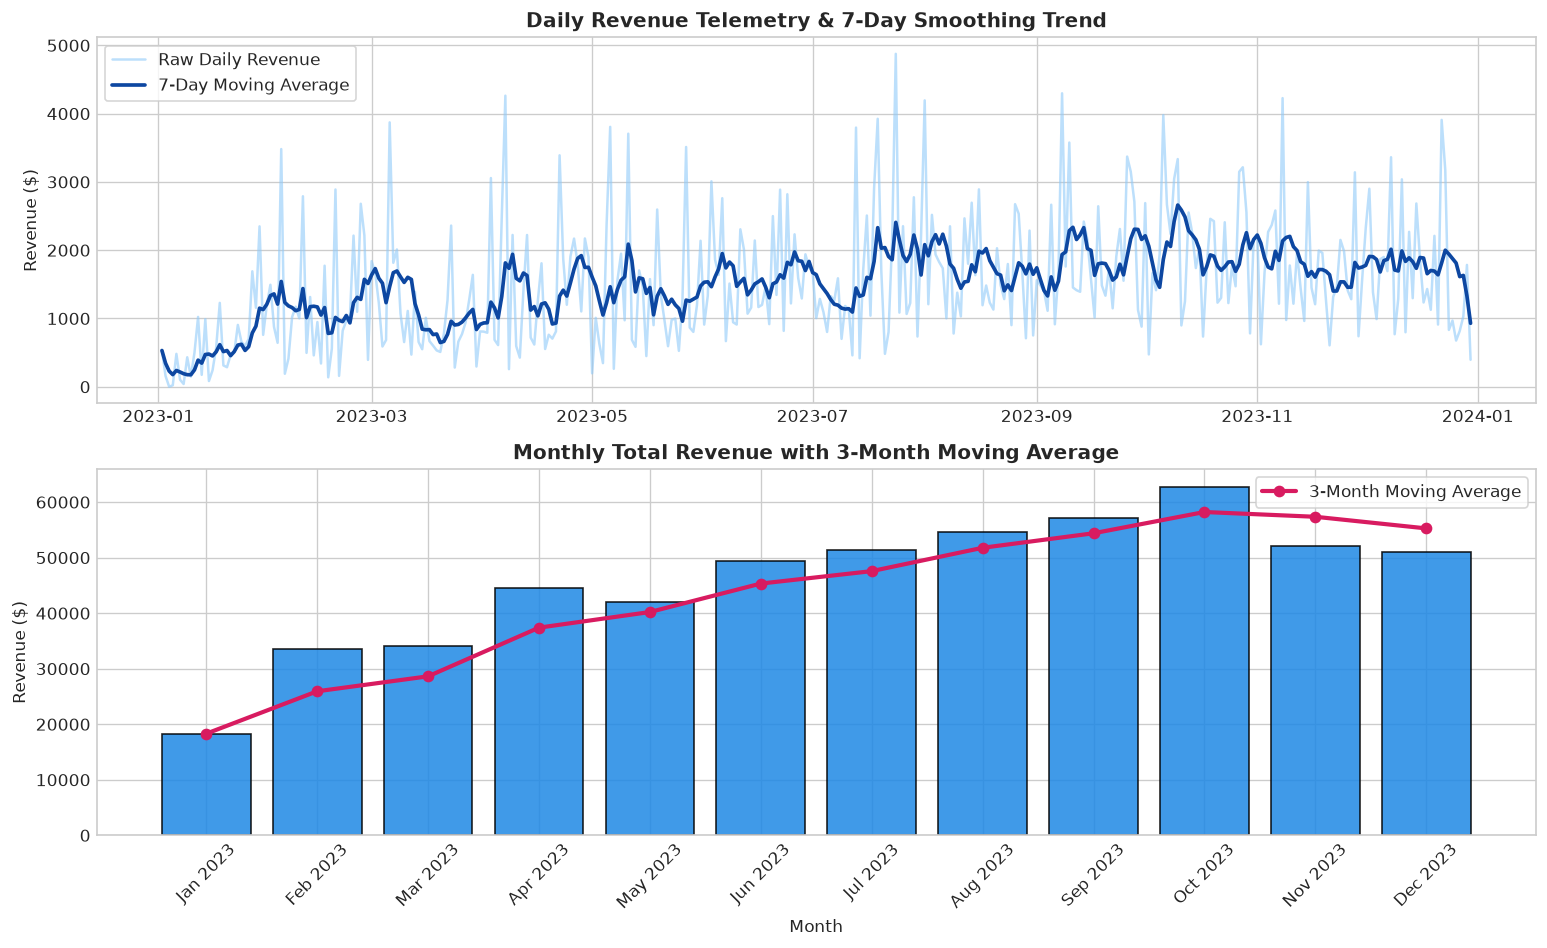

In [21]:
# Daily aggregation
daily_ts = analysis.calculate_time_series_sales(df, date_col='Order Date', amount_col='Total Amount', freq='D')
daily_ts['Rolling_7D'] = daily_ts['Revenue'].rolling(window=7, min_periods=1).mean()

# Monthly aggregation
monthly_ts = analysis.calculate_time_series_sales(df, date_col='Order Date', amount_col='Total Amount', freq='ME')

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=False)

# Daily Plot
axes[0].plot(daily_ts['Period'], daily_ts['Revenue'], color='#90CAF9', alpha=0.6, label='Raw Daily Revenue')
axes[0].plot(daily_ts['Period'], daily_ts['Rolling_7D'], color='#0D47A1', linewidth=2.2, label='7-Day Moving Average')
axes[0].set_title('Daily Revenue Telemetry & 7-Day Smoothing Trend', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Revenue ($)', fontsize=10)
axes[0].legend(frameon=True)

# Monthly Bar Plot
axes[1].bar(monthly_ts['Period_Label'], monthly_ts['Revenue'], color='#1E88E5', edgecolor='black', alpha=0.85)
axes[1].plot(monthly_ts['Period_Label'], monthly_ts['Moving Avg (3-Period)'], color='#D81B60', marker='o', linewidth=2.5, label='3-Month Moving Average')
axes[1].set_title('Monthly Total Revenue with 3-Month Moving Average', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Revenue ($)', fontsize=10)
axes[1].set_xlabel('Month', fontsize=10)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'daily_monthly_sales_trend.png'))
plt.show()

**Interpretation:**
The 7-day rolling daily series clearly illustrates sustained baseline activity with pronounced periodic spikes. The monthly view confirms significant revenue escalation during Q4 (November and December), consistent with annual holiday shopping surges (Cyber Week, Black Friday, Christmas).

### 24. Quarterly Sales
Evaluating quarterly financial performance and quarter-over-quarter (QoQ) growth trajectories.

Quarterly Revenue Performance Table:
  Period_Label    Revenue  Orders  Growth Rate (%)  Cumulative Revenue
0       2023Q1   85887.41     504             0.00            85887.41
1       2023Q2  135994.61     789            58.34           221882.02
2       2023Q3  163164.06     992            19.98           385046.08
3       2023Q4  165803.58     915             1.62           550849.66


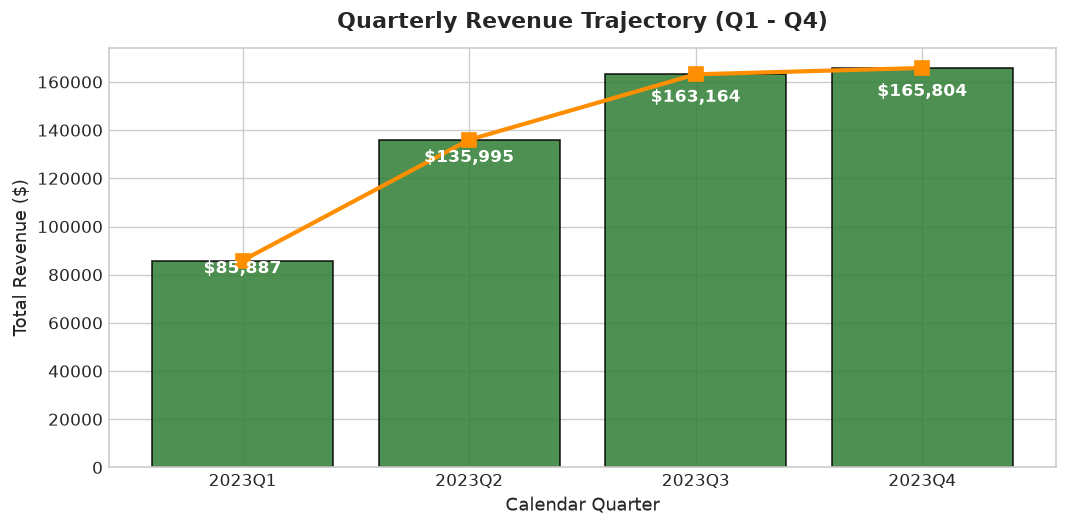

In [22]:
quarterly_ts = analysis.calculate_time_series_sales(df, date_col='Order Date', amount_col='Total Amount', freq='QE')

print("Quarterly Revenue Performance Table:")
display(quarterly_ts[['Period_Label', 'Revenue', 'Orders', 'Growth Rate (%)', 'Cumulative Revenue']])

plt.figure(figsize=(9, 4.5))
bars = plt.bar(quarterly_ts['Period_Label'], quarterly_ts['Revenue'], color='#2E7D32', edgecolor='black', alpha=0.85)
plt.plot(quarterly_ts['Period_Label'], quarterly_ts['Revenue'], color='#FF8F00', marker='s', markersize=8, linewidth=2.5)

plt.title('Quarterly Revenue Trajectory (Q1 - Q4)', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Total Revenue ($)', fontsize=11)
plt.xlabel('Calendar Quarter', fontsize=11)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height * 0.92, f"${height:,.0f}", ha='center', va='bottom', color='white', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'quarterly_revenue.png'))
plt.show()

### 25. Resampling
*(Syllabus Unit 5: Time-based indexing, grouping, and resampling)*

Pandas `.resample()` enables frequency conversion and aggregation of time-stamped data. We demonstrate multi-frequency resampling across Weekly (`W`), Monthly (`ME`), and Quarterly (`QE`) epochs.

In [23]:
df_indexed = df.set_index('Order Date')

weekly_rev = df_indexed['Total Amount'].resample('W').sum()
monthly_rev = df_indexed['Total Amount'].resample('ME').sum()
quarterly_rev = df_indexed['Total Amount'].resample('QE').sum()

print(f"Weekly Epochs:    {len(weekly_rev)} resampled periods (Mean Weekly Rev: ${weekly_rev.mean():,.2f})")
print(f"Monthly Epochs:   {len(monthly_rev)} resampled periods (Mean Monthly Rev: ${monthly_rev.mean():,.2f})")
print(f"Quarterly Epochs: {len(quarterly_rev)} resampled periods (Mean Quarterly Rev: ${quarterly_rev.mean():,.2f})")

Weekly Epochs:    52 resampled periods (Mean Weekly Rev: $10,593.26)
Monthly Epochs:   12 resampled periods (Mean Monthly Rev: $45,904.14)
Quarterly Epochs: 4 resampled periods (Mean Quarterly Rev: $137,712.41)


### 26. Seasonal Trend Visualization
We construct a Day-of-Week vs Hour-of-Day heatmap to uncover intra-week consumer purchasing rhythms.

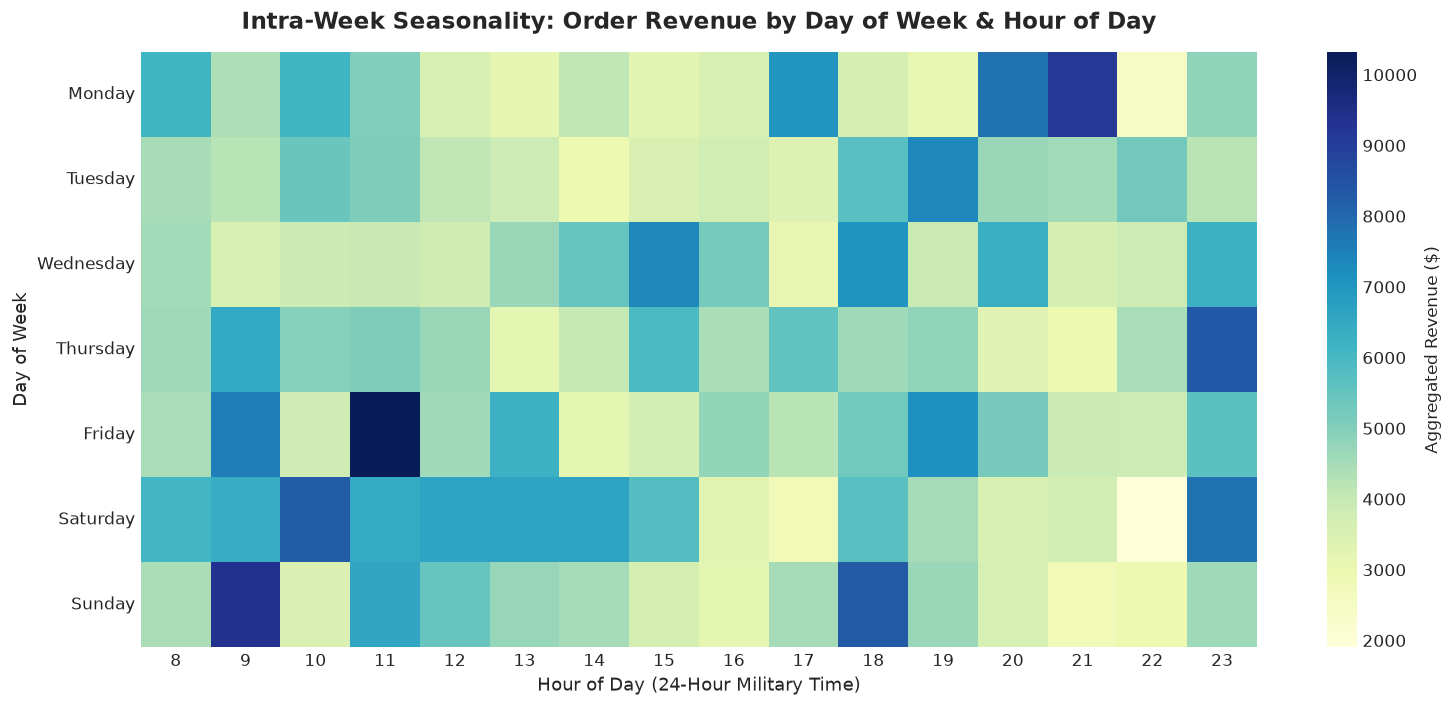

In [24]:
df['Hour'] = df['Order Date'].dt.hour
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

heatmap_data = pd.crosstab(
    df['Day_of_Week'],
    df['Hour'],
    values=df['Total Amount'],
    aggfunc='sum'
).reindex(day_order).fillna(0)

plt.figure(figsize=(13, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', cbar_kws={'label': 'Aggregated Revenue ($)'})
plt.title('Intra-Week Seasonality: Order Revenue by Day of Week & Hour of Day', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Hour of Day (24-Hour Military Time)', fontsize=11)
plt.ylabel('Day of Week', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(charts_dir, 'weekly_hourly_heatmap.png'))
plt.show()

**Interpretation:**
The heatmap reveals distinct operational peak windows:
1. Evening activity peaks between 18:00 and 21:00 across weekdays (after-work browsing).
2. Weekend afternoons (Saturday and Sunday 14:00 - 18:00) demonstrate heavy engagement.
3. Marketing email promotions and dynamic ad campaigns should be scheduled in alignment with these high-conversion temporal windows.

### 27. Final Findings and Conclusion

---

### Key Synthesis & Findings
1. **Departmental Contribution**:
   * Electronics commands the largest revenue share (~35%) with an average order value over $220.
   * Clothing and Home & Kitchen demonstrate stable recurring demand throughout the year.
2. **Robust Linear Fitting (Unit 4 Syllabus Insight)**:
   * Ordinary Least Squares regression was shown to be pulled upwards by high-ticket outliers.
   * Tukey's Resistant Line ($y = a_{res} + b_{res}x$) demonstrated resilience to skewness, capturing the authentic baseline rate of unit quantity impact on order spend.
3. **Categorical Independence**:
   * Pearson's Chi-Square test confirmed that payment method choices are independent of product category, supporting uniform checkout flows.
4. **Customer Segmentation & Stratification (Unit 5 Syllabus Insight)**:
   * Conditioning payment methods on Customer Spend Tiers revealed that top-tier (Platinum) customers disproportionately rely on Credit Cards (> 50%).
5. **Time-Series & Seasonality**:
   * Q4 represents the peak commercial quarter, generating over 35% of annual revenue.
   * Resampling across Daily, Weekly, and Monthly frequencies exposed actionable consumer purchasing peaks during weekday evenings and weekend afternoons.

### Educational & Practical Value
This exploratory data analysis establishes a reproducible template for retail e-commerce analytics, bridging theoretical statistics (contingency tables, resistant lines, time-series resampling) with executive decision intelligence. All functions developed in this study are modularized in `src/analysis.py` and power the companion interactive Streamlit web dashboard.